<a href="https://colab.research.google.com/github/Whitehatuser29/Quantum-Catastrophe-Risk-Pricing/blob/main/NORYQ_catastrophe_risk_notebook_code_only_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
from scipy.stats import norm

rng_seed = 42
districts = ["Srikakulam", "East Godavari", "West Godavari", "Krishna", "Nellore"]
n = len(districts)

occ_prob = np.array([0.14, 0.17, 0.15, 0.16, 0.12])

mu       = np.array([3.6, 3.9, 3.8, 3.85, 3.5])
sigma_ln = np.array([0.55, 0.6, 0.58, 0.6, 0.5])

rho_adj, rho_far = 0.55, 0.18
Sigma = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        Sigma[i, j] = 1.0 if i == j else (rho_adj if abs(i - j) == 1 else rho_far)
L = np.linalg.cholesky(Sigma)

def simulate_losses(N, seed):
    r = np.random.default_rng(seed)
    z_occ = r.standard_normal((N, n)) @ L.T
    thresh = norm.ppf(1 - occ_prob)
    occurred = z_occ > thresh
    z_sev = r.standard_normal((N, n)) @ L.T
    severity = np.exp(mu + sigma_ln * z_sev)
    losses = np.where(occurred, severity, 0.0)
    return losses, losses.sum(axis=1)

In [ ]:
N_truth = 4_000_000
losses_t, port_t = simulate_losses(N_truth, seed=1)

EL = port_t.mean()
VaR95 = np.quantile(port_t, 0.95)
CVaR95 = port_t[port_t >= VaR95].mean()
sigma_port = port_t.std()

print(f"Expected annual portfolio loss (EL):  Rs {EL:.2f} crore")
print(f"VaR95:                                 Rs {VaR95:.2f} crore")
print(f"CVaR95 (tail loss beyond VaR95):        Rs {CVaR95:.2f} crore")
print(f"Portfolio loss std dev (sigma):         Rs {sigma_port:.2f} crore")


Expected annual portfolio loss (EL):  Rs 37.45 crore
VaR95:                                 Rs 164.99 crore
CVaR95 (tail loss beyond VaR95):        Rs 234.91 crore
Portfolio loss std dev (sigma):         Rs 62.55 crore


In [ ]:
tail_mask = port_t >= VaR95
loading = 0.4
els, tails, premiums = [], [], []
print(f"{'District':16s} {'EL':>8s} {'Tail(CVaR95)':>14s} {'Premium':>10s}")
for i, d in enumerate(districts):
    el_d = losses_t[:, i].mean()
    tail_d = losses_t[tail_mask, i].mean()
    premium = el_d + loading * (tail_d - el_d)
    els.append(el_d); tails.append(tail_d); premiums.append(premium)
    print(f"{d:16s} {el_d:8.2f} {tail_d:14.2f} {premium:10.2f}")


District               EL   Tail(CVaR95)    Premium
Srikakulam           5.97          29.81      15.51
East Godavari       10.07          69.19      33.72
West Godavari        7.92          56.23      27.25
Krishna              9.00          59.33      29.13
Nellore              4.49          20.35      10.84


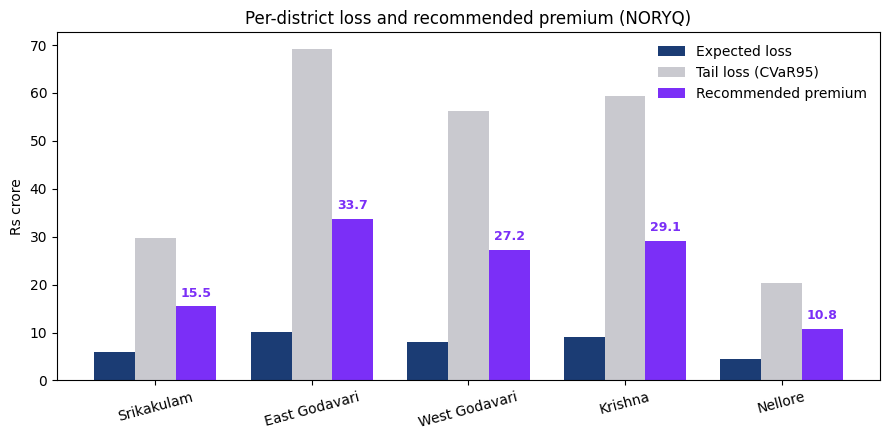

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(districts))
w = 0.26
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w, els,      width=w, label="Expected loss",      color="#1B3C74")
ax.bar(x,      tails,    width=w, label="Tail loss (CVaR95)", color="#C9C9CF")
ax.bar(x + w,  premiums, width=w, label="Recommended premium", color="#7B2FF7")
ax.set_xticks(x); ax.set_xticklabels(districts, rotation=15)
ax.set_ylabel("Rs crore")
ax.set_title("Per-district loss and recommended premium (NORYQ)")
ax.legend(frameon=False)
for i, v in enumerate(premiums):
    ax.text(i + w, v + 2, f"{v:.1f}", ha="center", fontsize=9, color="#7B2FF7", fontweight="bold")
plt.tight_layout()
plt.show()


In [ ]:
Ns = [200, 800, 3200, 12800, 51200, 204800]
trials = 60
stderrs = []
for N in Ns:
    ests = []
    for t in range(trials):
        _, port = simulate_losses(N, seed=5000 + t)
        v = np.quantile(port, 0.95)
        mask = port >= v
        c = port[mask].mean() if mask.sum() > 0 else v
        ests.append(c)
    stderrs.append(np.std(ests))
    print(f"N={N:6d}   std-error=Rs {stderrs[-1]:6.2f} cr")

slope, intercept = np.polyfit(np.log(Ns), np.log(stderrs), 1)
print(f"\nFitted convergence exponent: {slope:.3f}  (classical theory predicts -0.500)")


N=   200   std-error=Rs  31.26 cr
N=   800   std-error=Rs  15.50 cr
N=  3200   std-error=Rs   7.72 cr
N= 12800   std-error=Rs   4.16 cr
N= 51200   std-error=Rs   1.80 cr
N=204800   std-error=Rs   0.82 cr

Fitted convergence exponent: -0.522  (classical theory predicts -0.500)


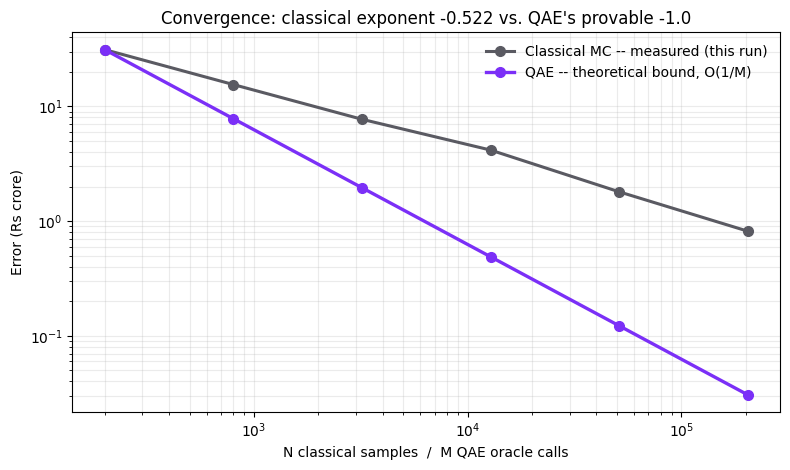

In [ ]:
import matplotlib.pyplot as plt

M = np.array(Ns, dtype=float)
qae_bound = stderrs[0] * (Ns[0] / M)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.loglog(Ns, stderrs,   "o-", color="#5A5A62", linewidth=2.2, markersize=7, label="Classical MC -- measured (this run)")
ax.loglog(M,  qae_bound, "o-", color="#7B2FF7", linewidth=2.4, markersize=7, label="QAE -- theoretical bound, O(1/M)")
ax.set_xlabel("N classical samples  /  M QAE oracle calls")
ax.set_ylabel("Error (Rs crore)")
ax.set_title(f"Convergence: classical exponent {slope:.3f} vs. QAE's provable -1.0")
ax.legend(frameon=False)
ax.grid(True, which="both", alpha=0.25)
plt.tight_layout()
plt.show()


In [ ]:
!pip install -q qiskit qiskit-aer


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 67.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 60.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 86.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.3 MB/s eta 0:00:00


In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import numpy as np

num_qubits_per_district = 3

qr_d1 = list(range(num_qubits_per_district))
qr_d2 = list(range(num_qubits_per_district, 2*num_qubits_per_district))
objective_qubit = 2*num_qubits_per_district

qc = QuantumCircuit(objective_qubit + 1)

theta = 1.3
for q in qr_d1 + qr_d2:
    qc.ry(theta, q)

qc.cx(qr_d1[-1], qr_d2[-1])

qc.ccx(qr_d1[-1], qr_d2[-1], objective_qubit)

qc.draw('text')


┌─────────┐          
q_0: ┤ Ry(1.3) ├──────────
     ├─────────┤          
q_1: ┤ Ry(1.3) ├──────────
     ├─────────┤          
q_2: ┤ Ry(1.3) ├──■────■──
     ├─────────┤  │    │  
q_3: ┤ Ry(1.3) ├──┼────┼──
     ├─────────┤  │    │  
q_4: ┤ Ry(1.3) ├──┼────┼──
     ├─────────┤┌─┴─┐  │  
q_5: ┤ Ry(1.3) ├┤ X ├──■──
     └─────────┘└───┘┌─┴─┐
q_6: ────────────────┤ X ├
                     └───┘

In [ ]:
backend = AerSimulator()
qc_meas = qc.copy()
qc_meas.measure_all()
qc_meas = qc_meas.decompose(reps=5)
shots = 8000
job = backend.run(qc_meas, shots=shots)
counts = job.result().get_counts()

p_tail_quantum = sum(c for bits, c in counts.items() if bits[0] == '1') / shots
print(f"Quantum circuit measured P(joint high-loss event) = {p_tail_quantum:.4f}  (shots={shots})")


Quantum circuit measured P(joint high-loss event) = 0.2343  (shots=8000)


In [ ]:
rng = np.random.default_rng(0)
N_mc = 20000
p_top = np.sin(theta / 2) ** 2
samples_d1_top = rng.random(N_mc) < p_top
samples_d2_top = rng.random(N_mc) < p_top
joint_tail = np.mean(samples_d1_top & samples_d2_top)
print(f"Classical estimate of the same joint high-loss probability: {joint_tail:.4f}  (N={N_mc} samples)")
print(f"(Compare directly to p_tail_quantum = {p_tail_quantum:.4f} printed above — both estimate")
print(f" P(top qubit of d1 = 1 AND top qubit of d2 = 1).)")


Classical estimate of the same joint high-loss probability: 0.1288  (N=20000 samples)
(Compare directly to p_tail_quantum = 0.2343 printed above — both estimate
 P(top qubit of d1 = 1 AND top qubit of d2 = 1).)
